# GPT-2 and Qwen2.5 comparison

This nb compares the completed 3 seed GPT-2 and Qwen2.5 SFT-to-GRPO results. GPT-2 XL and Qwen2.5 1.5B have the same nominal size and closely matched training settings, but still differ in architecture, tokenizer, pretraining. GPT-2 124M and Qwen2.5 0.5B are shown only as a lower scale context because their sizes and training parameterization are different.

In [7]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from matplotlib.lines import Line2D

ROOT = Path.cwd()
while not (ROOT / 'config.py').exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
assert (ROOT / 'config.py').exists(), 'run this notebook from the code repository'

RESULTS = ROOT / 'results'
FIG = ROOT / 'analysis' / 'figures' / '046_1'
FIG.mkdir(parents=True, exist_ok=True)
SEEDS = (0, 1, 2)
TIERS = ('easy', 'medium', 'hard')
MODELS = (
    {'model': 'GPT-2 124M', 'short': 'GPT-2\n124M', 'family': 'GPT-2',
     'scale': '124M', 'directory': '042_COLAB_FULL_M124_sft_grpo_seed{seed}',
     'complete': '042_arm_complete.json', 'comparison': 'lower-scale context'},
    {'model': 'Qwen2.5 0.5B', 'short': 'Qwen2.5\n0.5B', 'family': 'Qwen2.5',
     'scale': '0.5B', 'directory': '006_COLAB_FULL_B05_sft_grpo_seed{seed}',
     'complete': 'manifest.json', 'comparison': 'lower-scale context'},
    {'model': 'GPT-2 XL', 'short': 'GPT-2 XL\n1.5B', 'family': 'GPT-2',
     'scale': '1.5B', 'directory': '046_COLAB_FULL_GPT2_B15_sft_grpo_seed{seed}',
     'complete': '046_arm_complete.json', 'comparison': 'same nominal size'},
    {'model': 'Qwen2.5 1.5B', 'short': 'Qwen2.5\n1.5B', 'family': 'Qwen2.5',
     'scale': '1.5B', 'directory': '009_COLAB_FULL_B15_sft_grpo_seed{seed}',
     'complete': 'manifest.json', 'comparison': 'same nominal size'},
)
MODEL_ORDER = [item['model'] for item in MODELS]
MODEL_LABELS = [item['short'] for item in MODELS]
MODEL_COLORS = dict(zip(MODEL_ORDER, ('#4C78A8', '#F58518', '#72B7B2', '#E45756')))
SEED_COLORS = {0: '#4C78A8', 1: '#F58518', 2: '#54A24B'}

def read_json(path):
    with open(path) as f:
        return json.load(f)

def read_rows(path):
    with open(path) as f:
        return [json.loads(line) for line in f if line.strip()]

def accuracy(rows):
    return float(np.mean([bool(row['correct']) for row in rows]))

plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 10})

In [ ]:
# load 3 completed seeds for each model
runs = {}
endpoint_rows = []
delta_rows = []
tier_rows = []

for spec in MODELS:
    runs[spec['model']] = {}
    for seed in SEEDS:
        result_dir = RESULTS / spec['directory'].format(seed=seed)
        assert (result_dir / spec['complete']).exists(), f'{result_dir}: incomplete arm'
        branches = {}
        for branch, stage in (('sft', 'SFT'), ('grpo', 'GRPO')):
            rows = read_rows(result_dir / f'{branch}_preds.jsonl')
            probe_rows = read_rows(result_dir / f'{branch}_logprob_preds.jsonl')
            metrics = read_json(result_dir / f'{branch}_eval.json')
            assert len(rows) == len(probe_rows) == 1884
            assert [(row['subject'], row['tier'], row['gold']) for row in rows] == [
                (row['subject'], row['tier'], row['gold']) for row in probe_rows]
            branches[branch] = {'rows': rows, 'probe_rows': probe_rows, 'metrics': metrics}
            endpoint_rows.append({
                'model': spec['model'], 'family': spec['family'], 'scale': spec['scale'],
                'seed': seed, 'stage': stage, 'generative': accuracy(rows),
                'probe': accuracy(probe_rows),
                'format compliance': metrics['format_compliance'],
                'extraction coverage': 1 - metrics['extraction_failure_rate'],
                'hard accuracy': metrics['per_tier_acc']['hard'],
            })
        runs[spec['model']][seed] = branches
        delta_rows.append({
            'model': spec['model'], 'family': spec['family'], 'scale': spec['scale'],
            'seed': seed,
            'generative delta': accuracy(branches['grpo']['rows']) - accuracy(branches['sft']['rows']),
            'probe delta': accuracy(branches['grpo']['probe_rows']) - accuracy(branches['sft']['probe_rows']),
        })
        for tier in TIERS:
            before = [row for row in branches['sft']['rows'] if row['tier'] == tier]
            after = [row for row in branches['grpo']['rows'] if row['tier'] == tier]
            tier_rows.append({
                'model': spec['model'], 'seed': seed, 'tier': tier,
                'delta': accuracy(after) - accuracy(before),
            })

endpoint_df = pd.DataFrame(endpoint_rows)
delta_df = pd.DataFrame(delta_rows)
tier_df = pd.DataFrame(tier_rows)
assert len(endpoint_df) == 24 and len(delta_df) == 12 and len(tier_df) == 36

design_df = pd.DataFrame([{
    'model': item['model'], 'scale': item['scale'], 'comparison': item['comparison'],
    'seeds': 3,
} for item in MODELS])
display(design_df)

,model,scale,comparison,seeds
0,GPT-2 124M,124M,lower-scale context,3
1,Qwen2.5 0.5B,0.5B,lower-scale context,3
2,GPT-2 XL,1.5B,same nominal size,3
3,Qwen2.5 1.5B,1.5B,same nominal size,3


## Endpoint comparison

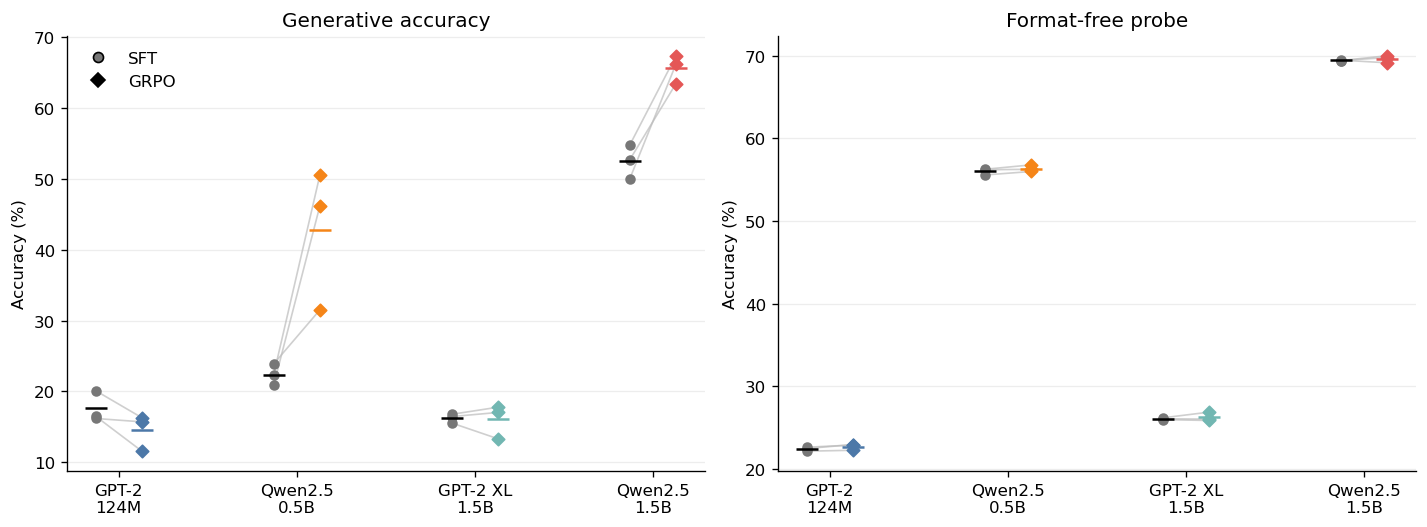

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ('generative', 'probe'),
                             ('Generative accuracy', 'Format-free probe')):
    for x, model in enumerate(MODEL_ORDER):
        frame = endpoint_df[endpoint_df.model == model]
        for seed in SEEDS:
            values = frame[frame.seed == seed].set_index('stage').loc[['SFT', 'GRPO'], metric]
            ax.plot((x - .13, x + .13), values.to_numpy() * 100, color='#BBBBBB',
                    linewidth=1, alpha=.7)
            ax.scatter(x - .13, values.iloc[0] * 100, color='#777777',
                       marker='o', s=28, zorder=3)
            ax.scatter(x + .13, values.iloc[1] * 100, color=MODEL_COLORS[model],
                       marker='D', s=28, zorder=3)
        means = frame.groupby('stage')[metric].mean()
        ax.scatter(x - .13, means['SFT'] * 100, color='black', marker='_', s=180, zorder=4)
        ax.scatter(x + .13, means['GRPO'] * 100, color=MODEL_COLORS[model],
                   marker='_', s=180, zorder=4)
    ax.set_xticks(range(len(MODEL_ORDER)), MODEL_LABELS)
    ax.set_ylabel('Accuracy (%)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.22)
axes[0].legend(handles=(
    Line2D([0], [0], marker='o', color='none', markerfacecolor='#777777', label='SFT'),
    Line2D([0], [0], marker='D', color='none', markerfacecolor='black', label='GRPO'),
), frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig01_endpoints.png', bbox_inches='tight')
plt.show()

## GRPO changes

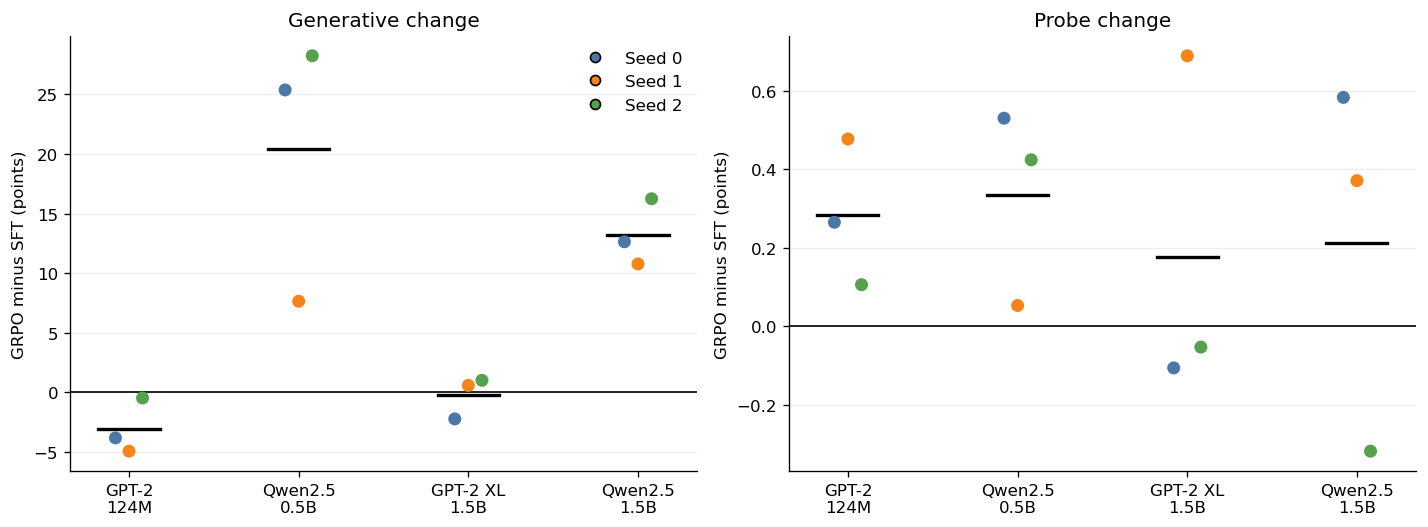

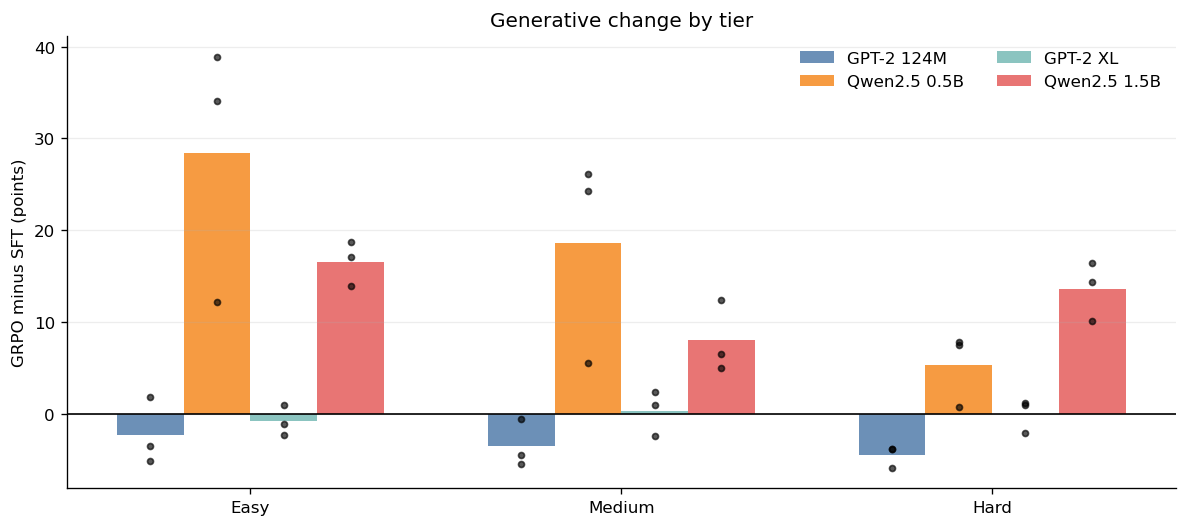

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ('generative delta', 'probe delta'),
                             ('Generative change', 'Probe change')):
    for x, model in enumerate(MODEL_ORDER):
        frame = delta_df[delta_df.model == model].sort_values('seed')
        offsets = np.linspace(-.08, .08, len(frame))
        ax.scatter(x + offsets, frame[metric] * 100,
                   c=[SEED_COLORS[seed] for seed in frame.seed], s=46, zorder=3)
        mean = frame[metric].mean() * 100
        ax.plot((x - .18, x + .18), (mean, mean), color='black', linewidth=2)
    ax.axhline(0, color='black', linewidth=1)
    ax.set_xticks(range(len(MODEL_ORDER)), MODEL_LABELS)
    ax.set_ylabel('GRPO minus SFT (points)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.22)
axes[0].legend(handles=[Line2D([0], [0], marker='o', color='none',
                                   markerfacecolor=SEED_COLORS[seed], label=f'Seed {seed}')
                        for seed in SEEDS], frameon=False)
fig.tight_layout()
fig.savefig(FIG / 'fig02_grpo_changes.png', bbox_inches='tight')
plt.show()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(TIERS))
width = .18
for index, model in enumerate(MODEL_ORDER):
    frame = tier_df[tier_df.model == model]
    means = frame.groupby('tier').delta.mean().reindex(TIERS) * 100
    position = x + (index - 1.5) * width
    ax.bar(position, means, width=width, color=MODEL_COLORS[model],
           alpha=.82, label=model)
    for tier_index, tier in enumerate(TIERS):
        values = frame[frame.tier == tier].sort_values('seed').delta * 100
        ax.scatter(np.full(len(values), position[tier_index]), values,
                   color='black', s=13, alpha=.65, zorder=3)
ax.axhline(0, color='black', linewidth=1)
ax.set_xticks(x, [tier.title() for tier in TIERS])
ax.set_ylabel('GRPO minus SFT (points)')
ax.set_title('Generative change by tier')
ax.legend(frameon=False, ncol=2)
ax.grid(axis='y', alpha=.22)
fig.tight_layout()
fig.savefig(FIG / 'fig03_tier_changes.png', bbox_inches='tight')
plt.show()

## Response measures

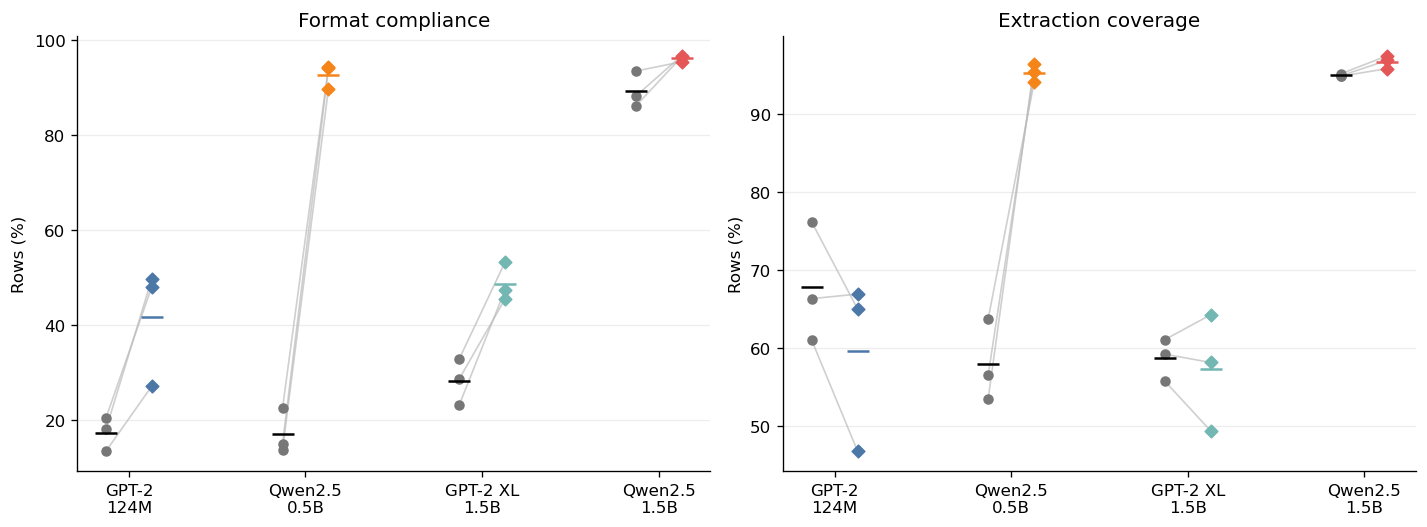

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, metric, title in zip(axes, ('format compliance', 'extraction coverage'),
                             ('Format compliance', 'Extraction coverage')):
    for x, model in enumerate(MODEL_ORDER):
        frame = endpoint_df[endpoint_df.model == model]
        for seed in SEEDS:
            values = frame[frame.seed == seed].set_index('stage').loc[['SFT', 'GRPO'], metric]
            ax.plot((x - .13, x + .13), values.to_numpy() * 100, color='#BBBBBB',
                    linewidth=1, alpha=.7)
            ax.scatter(x - .13, values.iloc[0] * 100, color='#777777',
                       marker='o', s=28, zorder=3)
            ax.scatter(x + .13, values.iloc[1] * 100, color=MODEL_COLORS[model],
                       marker='D', s=28, zorder=3)
        means = frame.groupby('stage')[metric].mean()
        ax.scatter(x - .13, means['SFT'] * 100, color='black', marker='_', s=180, zorder=4)
        ax.scatter(x + .13, means['GRPO'] * 100, color=MODEL_COLORS[model],
                   marker='_', s=180, zorder=4)
    ax.set_xticks(range(len(MODEL_ORDER)), MODEL_LABELS)
    ax.set_ylabel('Rows (%)')
    ax.set_title(title)
    ax.grid(axis='y', alpha=.22)
fig.tight_layout()
fig.savefig(FIG / 'fig04_response_measures.png', bbox_inches='tight')
plt.show()

## Values

In [12]:
summary_rows = []
for spec in MODELS:
    frame = endpoint_df[endpoint_df.model == spec['model']]
    sft = frame[frame.stage == 'SFT']
    grpo = frame[frame.stage == 'GRPO']
    change = delta_df[delta_df.model == spec['model']]
    summary_rows.append({
        'model': spec['model'],
        'SFT generative (%)': sft.generative.mean() * 100,
        'GRPO generative (%)': grpo.generative.mean() * 100,
        'generative delta (pt)': change['generative delta'].mean() * 100,
        'SFT probe (%)': sft.probe.mean() * 100,
        'GRPO probe (%)': grpo.probe.mean() * 100,
        'probe delta (pt)': change['probe delta'].mean() * 100,
        'GRPO format (%)': grpo['format compliance'].mean() * 100,
        'GRPO coverage (%)': grpo['extraction coverage'].mean() * 100,
        'GRPO hard (%)': grpo['hard accuracy'].mean() * 100,
    })

summary_df = pd.DataFrame(summary_rows)
display(summary_df.style.format(precision=2))
display(delta_df.pivot(index='seed', columns='model', values='generative delta')
        .mul(100).style.format('{:+.2f}'))

summary_df.to_csv(FIG / '046_1_model_summary.csv', index=False)
endpoint_df.to_csv(FIG / '046_1_endpoints.csv', index=False)
delta_df.to_csv(FIG / '046_1_seed_changes.csv', index=False)
tier_df.to_csv(FIG / '046_1_tier_changes.csv', index=False)

,model,SFT generative (%),GRPO generative (%),generative delta (pt),SFT probe (%),GRPO probe (%),probe delta (pt),GRPO format (%),GRPO coverage (%),GRPO hard (%)
0,GPT-2 124M,17.60,14.53,-3.08,22.40,22.68,0.28,41.61,59.59,6.99
1,Qwen2.5 0.5B,22.36,42.78,20.42,56.02,56.35,0.34,92.71,95.28,23.48
2,GPT-2 XL,16.26,16.05,-0.21,26.06,26.24,0.18,48.62,57.29,9.01
3,Qwen2.5 1.5B,52.49,65.71,13.22,69.44,69.66,0.21,96.20,96.71,42.26


model,GPT-2 124M,GPT-2 XL,Qwen2.5 0.5B,Qwen2.5 1.5B
seed,,,,
0,-3.82,-2.23,+25.37,+12.63
1,-4.94,+0.58,+7.64,+10.77
2,-0.48,+1.01,+28.24,+16.24


## Cross-referenced conclusion

Across 3 seeds, GRPO raises Qwen2.5 generative accuracy by about 20.4 points at 0.5B and 13.2 points at 1.5B. The GPT-2 results are different - 124M falls by about 3.1 points and XL changes by about -0.2 points, while their format free probes stay nearly flat.

GPT-2 generative readings remain limited because extraction coverage changes too much in two seeds at each scale. And even with that limitation, the generative results and the probe do not show the large knowledge gains seen in Qwen2.5. GPT-2 XL and Qwen2.5 1.5B are the closest comparison, but this is still a comparison of complete pretrained model bundles rather than isolated architecture effect.